<a href="https://colab.research.google.com/github/esraabanisalman26-ui/CO2_dl_/blob/main/Co2_DL_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style="whitegrid")

DATA_PATH = "/content/drive/MyDrive/CO2 Emissions_Canada.csv"
TARGET = "CO2 Emissions(g/km)"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
raw = pd.read_csv(DATA_PATH)
print("raw shape:", raw.shape, "| missing:", int(raw.isna().sum().sum()), "| duplicates:", int(raw.duplicated().sum()))

df = raw.drop_duplicates().reset_index(drop=True)


DROP_COLS = ["Model",
    "Fuel Consumption City (L/100 km)",
    "Fuel Consumption Hwy (L/100 km)",
    "Fuel Consumption Comb (L/100 km)",
    "Fuel Consumption Comb (mpg)" 
 ]

df = df.drop(columns=DROP_COLS)
print("clean shape:", df.shape)

raw shape: (7385, 12) | missing: 0 | duplicates: 1103
removed rare Fuel Type: ['N']
clean shape: (6281, 9)


In [ ]:
train_df, tmp_df = train_test_split(df, test_size=0.30, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, random_state=SEED)  # لا تستخدمه إلا بالآخر

assert len(train_df) + len(val_df) + len(test_df) == len(df)
print("train / val / test:", len(train_df), len(val_df), len(test_df))

train / val / test: 4396 942 943


In [ ]:
eda = train_df.copy()
feature_cols = [c for c in eda.columns if c != TARGET]
num_cols = eda[feature_cols].select_dtypes("number").columns.tolist()
cat_cols = eda[feature_cols].select_dtypes(exclude="number").columns.tolist()
print("numeric:", num_cols)
print("categorical:", {c: eda[c].nunique() for c in cat_cols})

numeric: ['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)']
categorical: {'Make': 42, 'Vehicle Class': 16, 'Transmission': 27, 'Fuel Type': 4}


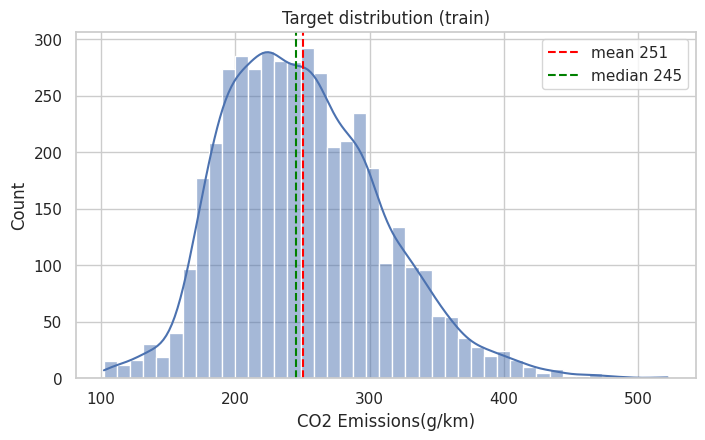

skewness: 0.56


In [ ]:
plt.figure(figsize=(8, 4.5))
sns.histplot(eda[TARGET], kde=True)
plt.axvline(eda[TARGET].mean(), color="red", ls="--", label=f"mean {eda[TARGET].mean():.0f}")
plt.axvline(eda[TARGET].median(), color="green", ls="--", label=f"median {eda[TARGET].median():.0f}")
plt.title("Target distribution (train)"); plt.legend(); plt.show()
print("skewness:", round(eda[TARGET].skew(), 2))

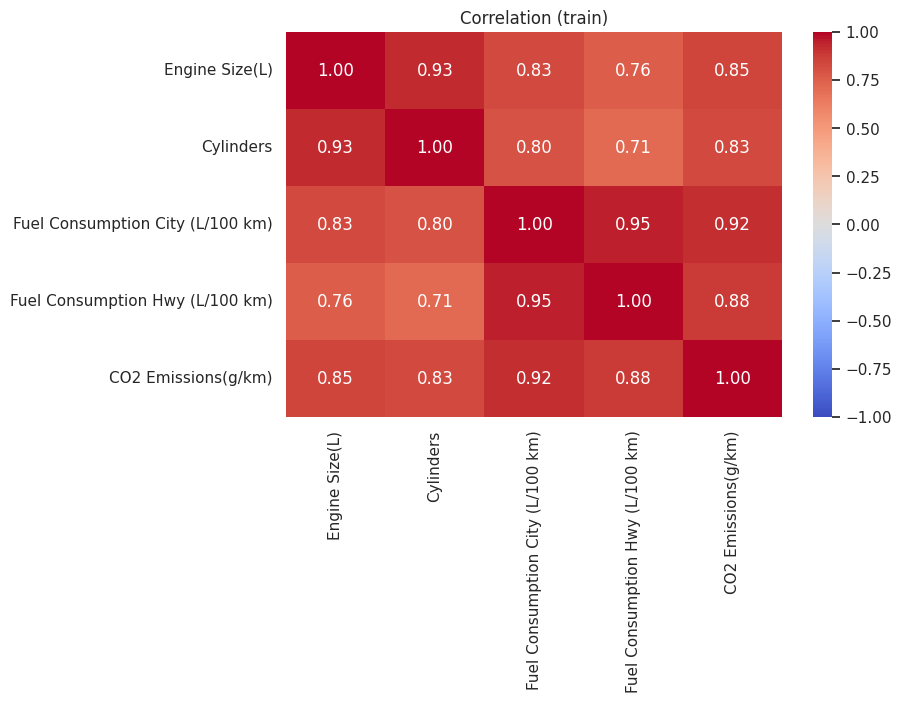

In [ ]:
plt.figure(figsize=(8, 5))
sns.heatmap(eda[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation (train)"); plt.show()

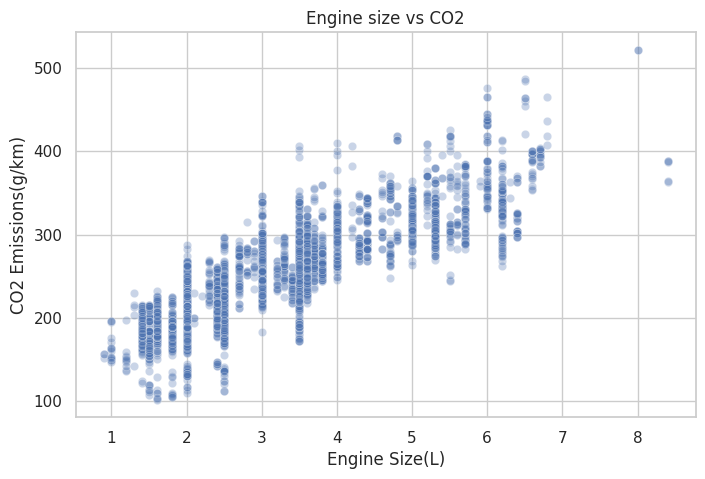

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=eda, x="Engine Size(L)", y=TARGET, alpha=0.3)
plt.title("Engine size vs CO2"); plt.show()

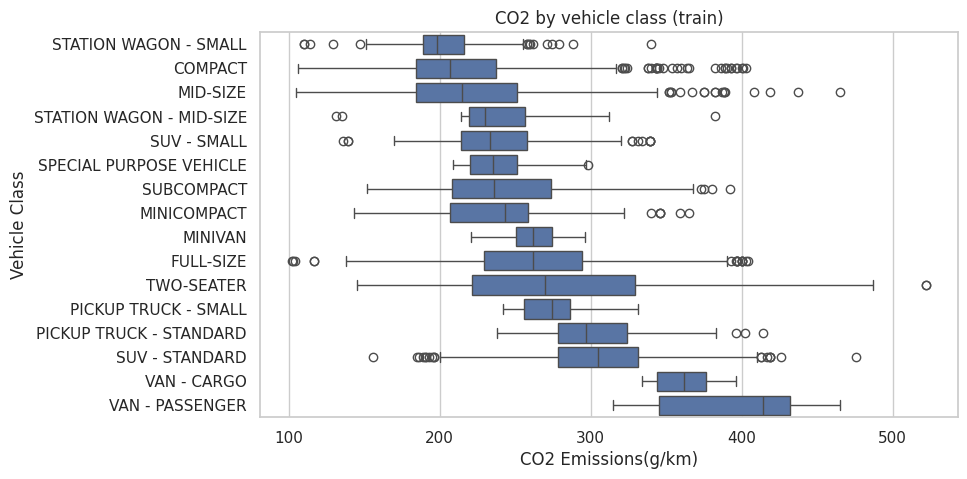

In [ ]:
order = eda.groupby("Vehicle Class")[TARGET].median().sort_values().index
plt.figure(figsize=(9, 5))
sns.boxplot(data=eda, x=TARGET, y="Vehicle Class", order=order)
plt.title("CO2 by vehicle class (train)"); plt.show()

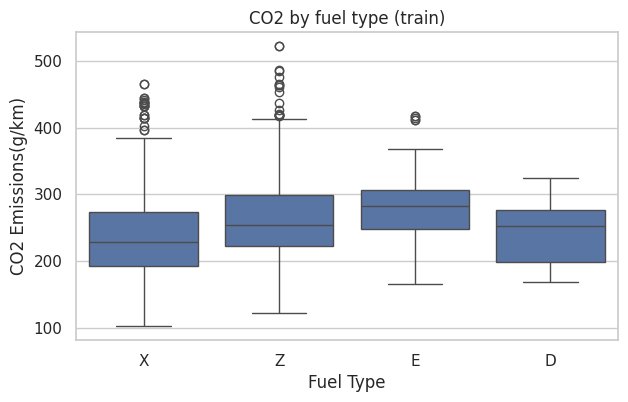

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=eda, x="Fuel Type", y=TARGET)
plt.title("CO2 by fuel type (train)"); plt.show()

In [ ]:
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_tr  = pre.fit_transform(train_df[feature_cols]).astype("float32")
X_val = pre.transform(val_df[feature_cols]).astype("float32")
X_te  = pre.transform(test_df[feature_cols]).astype("float32")

y_scaler = StandardScaler().fit(train_df[[TARGET]])
y_tr  = y_scaler.transform(train_df[[TARGET]]).ravel().astype("float32")
y_val = y_scaler.transform(val_df[[TARGET]]).ravel().astype("float32")
y_te  = y_scaler.transform(test_df[[TARGET]]).ravel().astype("float32")
STD = float(y_scaler.scale_[0])

print("features:", X_tr.shape[1], "| shapes:", X_tr.shape, X_val.shape, X_te.shape)

features: 93 | shapes: (4396, 93) (942, 93) (943, 93)


In [ ]:
t0 = time.time()
lin = LinearRegression().fit(X_tr, y_tr)
lin_time = time.time() - t0

# Predictions in scaled units
lin_train_pred = lin.predict(X_tr)
lin_val_pred = lin.predict(X_val)

# Convert predictions back to original CO2 units
lin_train_pred = y_scaler.inverse_transform(
    lin_train_pred.reshape(-1, 1)
).ravel()

lin_val_pred = y_scaler.inverse_transform(
    lin_val_pred.reshape(-1, 1)
).ravel()

# Calculate MSE in original units
lin_train = float(
    ((lin_train_pred - train_df[TARGET].values) ** 2).mean()
)

lin_val = float(
    ((lin_val_pred - val_df[TARGET].values) ** 2).mean()
)

print(f"Linear regression | train MSE: {lin_train:.1f} | val MSE: {lin_val:.1f} | time: {lin_time:.2f}s")

LIN_VAL = lin_val

# Largest 10 coefficients
coefs = pd.Series(lin.coef_, index=pre.get_feature_names_out())
print(coefs.sort_values(key=abs, ascending=False).head(10).round(3))

Linear regression | train MSE: 25.2 | val MSE: 25.6 | time: 0.04s
cat__Fuel Type_E                        -91.699997
cat__Fuel Type_D                         49.900002
num__Fuel Consumption City (L/100 km)    43.400002
num__Fuel Consumption Hwy (L/100 km)     22.000000
cat__Fuel Type_Z                         21.700001
cat__Fuel Type_X                         20.100000
cat__Transmission_A4                     -9.300000
cat__Transmission_AM9                     9.300000
cat__Make_BUGATTI                         9.100000
cat__Vehicle Class_VAN - PASSENGER       -7.200000
dtype: float32


In [ ]:
X_train_tensor = torch.tensor(X_tr, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)

y_train_tensor = torch.tensor(y_tr, dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

X_test_tensor = torch.tensor(X_te, dtype=torch.float32)
y_test_tensor = torch.tensor(y_te, dtype=torch.float32).reshape(-1, 1)

In [ ]:
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn
# 1. Create Dataset and DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# 2. Build Model
model = nn.Sequential(
    nn.Linear(X_tr.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

# 3. Loss and Optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05,
    momentum=0.9
)

# 4. Training
train_losses = []
val_losses = []

best_val_mse = float("inf")
best_epoch = 0

for epoch in range(100):

    model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:

        optimizer.zero_grad()

        y_pred = model(batch_X)

        loss = criterion(y_pred, batch_y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * len(batch_X)

    train_mse = total_loss / len(train_dataset)
    train_losses.append(train_mse)

    # Validation
    model.eval()

    with torch.no_grad():
        val_pred = model(X_val_tensor)
        val_loss = criterion(val_pred, y_val_tensor)

    val_losses.append(val_loss.item())

    # Save Best Model
    if val_loss.item() < best_val_mse:
        best_val_mse = val_loss.item()
        best_epoch = epoch + 1

        torch.save(model.state_dict(), "best_model.pth")

    print(f"Epoch [{epoch+1}/100], "
          f"Train MSE: {train_mse:.4f}, "
          f"Val MSE: {val_loss.item():.4f}")


# 5. Load Best Model
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

print("Best Validation MSE:", best_val_mse)
print("Best Epoch:", best_epoch)


# 6. Plot Loss
experiment_name = (
    f"Optimizer: SGD with Momentum | "
    f"Learning Rate: 0.05 | Batch Size: 64"
)

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.axhline(
    y=LIN_VAL / (STD ** 2),
    linestyle="--",
    label="Linear Regression"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(f"Experiment: {experiment_name}")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Final Test Evaluation
model.eval()

with torch.no_grad():
    y_pred = model(X_test_tensor).numpy()

y_true = y_test_tensor.numpy()

# Return to original CO2 scale
y_pred = y_scaler.inverse_transform(y_pred)
y_true = y_scaler.inverse_transform(y_true)

print("Final Test Results")
print("------------------")
print("Test MSE:", mean_squared_error(y_true, y_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
print("Test MAE:", mean_absolute_error(y_true, y_pred))
print("Test R2:", r2_score(y_true, y_pred))

In [ ]:
lin_pred = lin.predict(X_te)

lin_pred = y_scaler.inverse_transform(
    lin_pred.reshape(-1, 1)
).ravel()

print("Test MSE:", mean_squared_error(test_df[TARGET], lin_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(test_df[TARGET], lin_pred)))
print("Test MAE:", mean_absolute_error(test_df[TARGET], lin_pred))
print("Test R2:", r2_score(test_df[TARGET], lin_pred))